In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras
# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

from keras.layers import Activation, BatchNormalization, Conv2D, Conv2DTranspose, MaxPooling2D, Dropout
from model_base import ModelBase, plot_history, visualize_result
import cv2

In [2]:
class SimpleModel(ModelBase):
    def __init__(self):
        super().__init__('Ct32_2xC32')

    def create(self, inputs):
        net = Conv2DTranspose(32, 3, strides=2, padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

model = SimpleModel()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 67, 160, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 134, 320, 32)   │           896 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 134, 320, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 134, 320, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 134, 320, 3)    │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,875 (77.64 KB)

 Trainable params: 19,683 (76.89 KB)

 Non-trainable params: 192 (768.00 B)

In [3]:
history = model.fit()

Epoch 1/50
32/32 - 15s - 459ms/step - accuracy: 0.4196 - loss: 0.0181 - val_accuracy: 0.6347 - val_loss: 0.0774
Epoch 2/50
32/32 - 15s - 480ms/step - accuracy: 0.6473 - loss: 0.0053 - val_accuracy: 0.6064 - val_loss: 0.0821
Epoch 3/50
32/32 - 15s - 470ms/step - accuracy: 0.7117 - loss: 0.0039 - val_accuracy: 0.5552 - val_loss: 0.0854
Epoch 4/50
32/32 - 15s - 454ms/step - accuracy: 0.7351 - loss: 0.0036 - val_accuracy: 0.5730 - val_loss: 0.0834
Epoch 5/50
32/32 - 14s - 449ms/step - accuracy: 0.7324 - loss: 0.0031 - val_accuracy: 0.5693 - val_loss: 0.0817
Epoch 6/50
32/32 - 14s - 449ms/step - accuracy: 0.7429 - loss: 0.0030 - val_accuracy: 0.5556 - val_loss: 0.0788
Epoch 7/50
32/32 - 14s - 449ms/step - accuracy: 0.7357 - loss: 0.0031 - val_accuracy: 0.5240 - val_loss: 0.0716
Epoch 8/50
32/32 - 15s - 463ms/step - accuracy: 0.7556 - loss: 0.0029 - val_accuracy: 0.5170 - val_loss: 0.0670
Epoch 9/50
32/32 - 15s - 455ms/step - accuracy: 0.7450 - loss: 0.0031 - val_accuracy: 0.5026 - val_loss:

Train Acc      0.7556778788566589
Validation Acc 0.8597870469093323


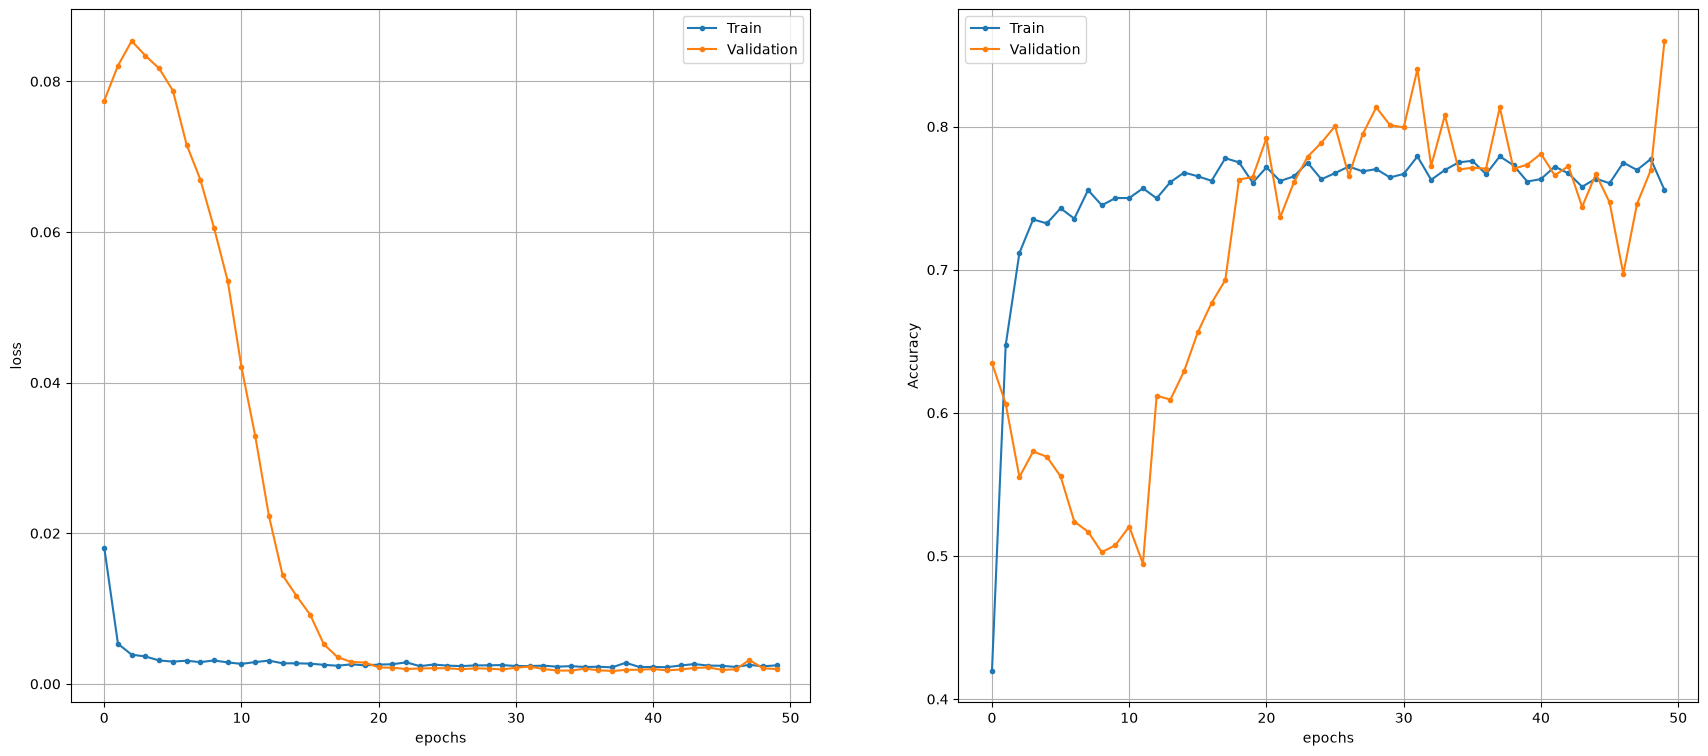

In [4]:
plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


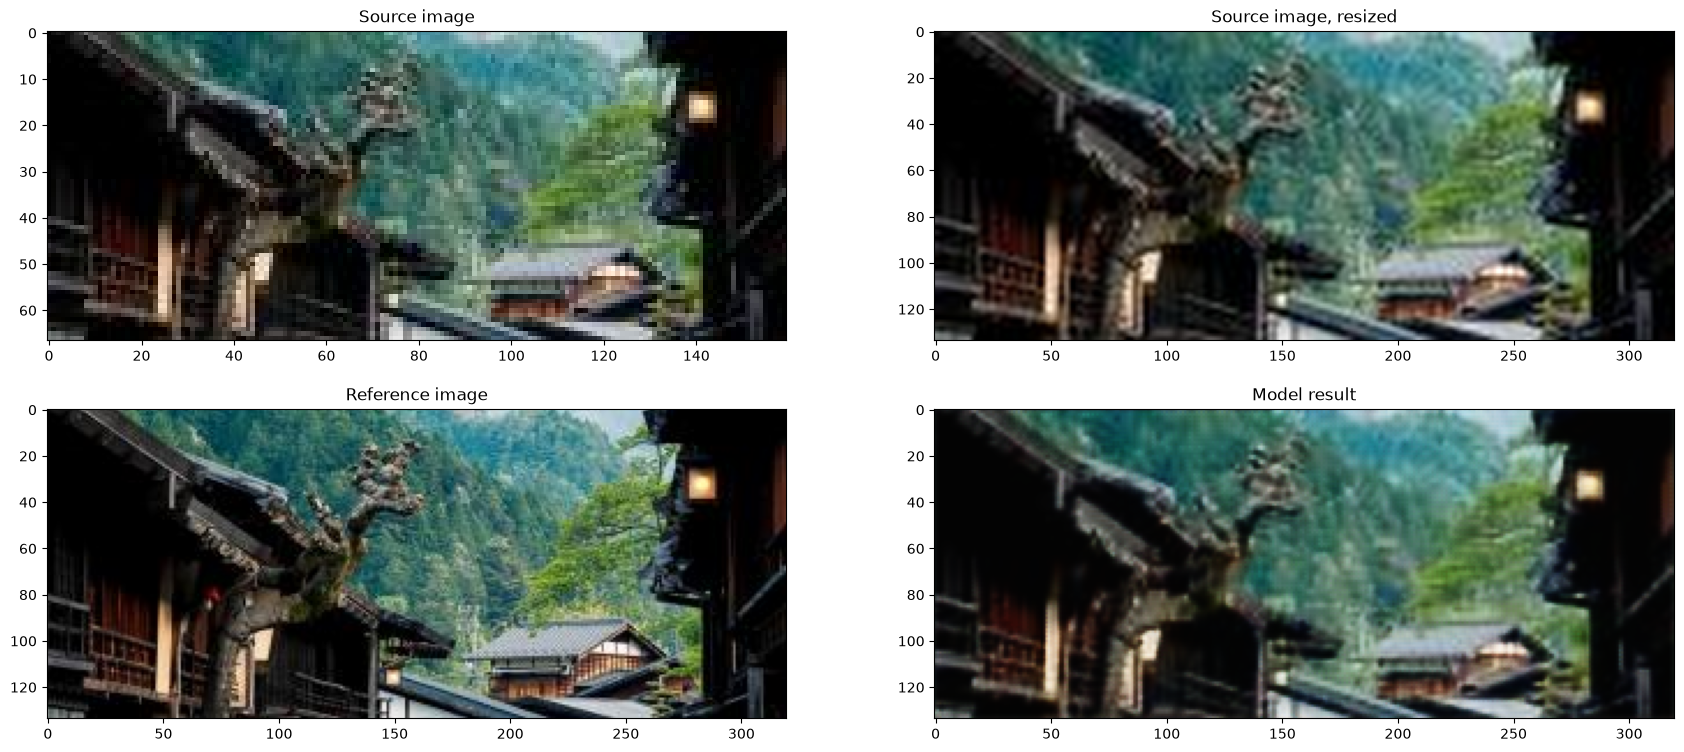

In [17]:
from dataset import Dataset
x = cv2.imread(os.path.join(Dataset.ROOT, 'test', '1.jpg')).astype(np.float32) / 255
y = cv2.imread(os.path.join(Dataset.ROOT, 'test', '2.jpg')).astype(np.float32) / 255
visualize_result(model, x, y)